In [13]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, losses, datasets

In [14]:
#Load MNIST
(x_train, _), (x_test, _) = datasets.mnist.load_data()

#Preprocess the data
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
x_train= x_train.reshape((-1,28*28))
x_test= x_test.reshape((-1,28*28))

In [15]:
# Hyperparameters 
input_dim=28*28
latent_dim=64
batch_size=256
epochs=30

In [16]:
#Encoder
encoder_inputs=layers.Input(shape=(input_dim,))
x=layers.Dense(512,activation='relu')(encoder_inputs)
x=layers.Dense(256,activation='relu')(x)
x=layers.Dense(128,activation='relu')(x)
z=layers.Dense(latent_dim,name='latent')(x)
encoder=models.Model(encoder_inputs,z,name='encoder')
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 64)             │         8,256 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 574,400 (2.19 MB)

 Trainable params: 574,400 (2.19 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
#Decoder
latent_inputs=layers.Input(shape=(latent_dim,))
x=layers.Dense(128,activation='relu')(latent_inputs)
x=layers.Dense(256,activation='relu')(x)
x=layers.Dense(512,activation='relu')(x)
decoder_outputs=layers.Dense(input_dim,activation='sigmoid')(x)
decoder=models.Model(latent_inputs,decoder_outputs,name='decoder')
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 784)            │       402,192 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 575,120 (2.19 MB)

 Trainable params: 575,120 (2.19 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
#Autoencoder (encoder+decoder)
ae_inputs=encoder_inputs
ae_outputs=decoder(encoder(ae_inputs))
autoencoder=models.Model(ae_inputs,ae_outputs,name='autoencoder')
autoencoder.compile(optimizer='adam',loss='binary_crossentropy', metrics=['Accuracy'])
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 64)             │       574,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 784)            │       575,120 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,149,520 (4.39 MB)

 Trainable params: 1,149,520 (4.39 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
#train
history=autoencoder.fit(
    x_train, x_train,
    epochs=epochs,
    batch_size=batch_size,
    shuffle=True,
    validation_data=(x_test, x_test)
)

Epoch 1/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - Accuracy: 0.0097 - loss: 0.2072 - val_Accuracy: 0.0100 - val_loss: 0.1392
Epoch 2/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - Accuracy: 0.0124 - loss: 0.1237 - val_Accuracy: 0.0133 - val_loss: 0.1119
Epoch 3/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - Accuracy: 0.0114 - loss: 0.1070 - val_Accuracy: 0.0125 - val_loss: 0.1002
Epoch 4/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - Accuracy: 0.0116 - loss: 0.0983 - val_Accuracy: 0.0128 - val_loss: 0.0944
Epoch 5/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - Accuracy: 0.0125 - loss: 0.0935 - val_Accuracy: 0.0131 - val_loss: 0.0911
Epoch 6/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - Accuracy: 0.0135 - loss: 0.0901 - val_Accuracy: 0.0122 - val_loss: 0.0898
Epoch 7/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - Accuracy: 0.0137 - loss: 0.0878 - val_Accuracy: 0.0159 - val_loss: 0.0869
Epoch 8/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - Accuracy: 0.0135 - loss: 0.0859 - val_Accu

In [20]:
#Visualize reconstructions
n=10
samples=x_test[10:n+10]
reconstructed=autoencoder.predict(samples)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step


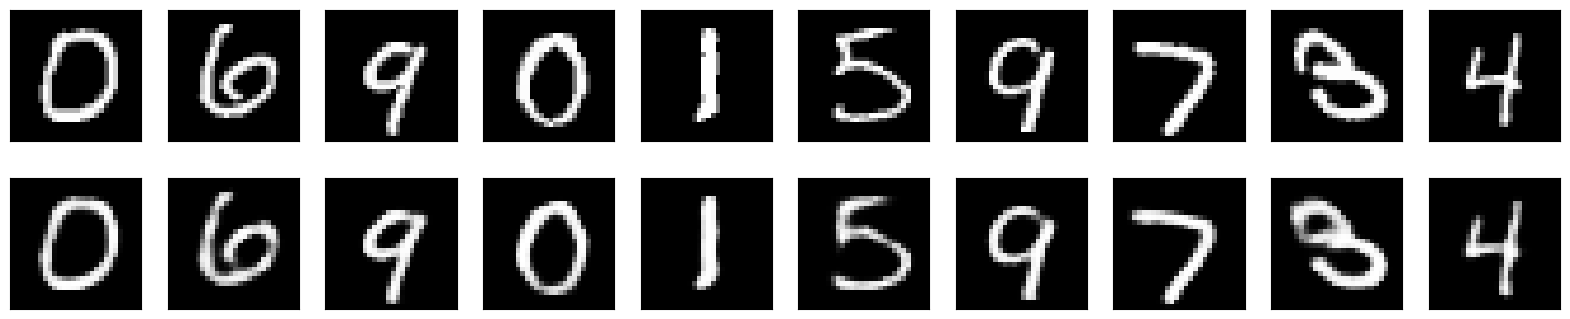

In [22]:
plt.figure(figsize=(20,4))
for i in range(n):
    #Original
    ax=plt.subplot(2,n,i+1)
    plt.imshow(samples[i].reshape(28,28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    #Reconstructed
    ax=plt.subplot(2,n,i+n+1)
    plt.imshow(reconstructed[i].reshape(28,28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()

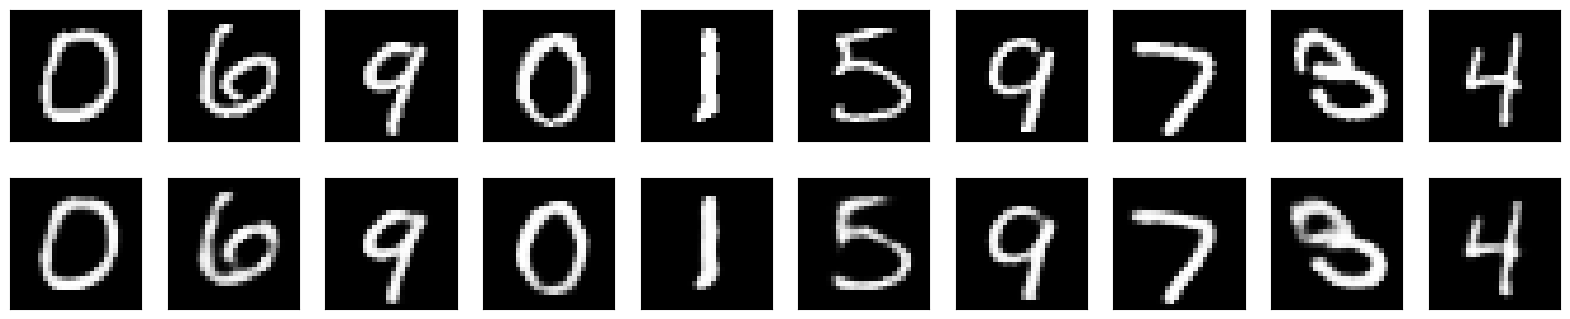